In [5]:
### 1.1 Import Pakete

In [6]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

# ML & Metriken
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, 
                             roc_curve, precision_recall_curve, roc_auc_score)
from imblearn.over_sampling import SMOTE

sns.set_style("darkgrid")
plt.rcParams['figure.figsize'] = (12, 6)
print("Alle Bibliotheken erfolgreich geladen!")

Alle Bibliotheken erfolgreich geladen!


In [7]:
### 1.2 Import Daten

In [8]:
import pandas as pd

print("Lade Datensätze...")

df_features = pd.read_csv('elliptic_txs_features.csv', header=None)
df_classes = pd.read_csv('elliptic_txs_classes.csv')
df_features.columns = ['txId', 'time_step'] + [f'feat_{i}' for i in range(165)]
df_nodes = pd.merge(df_features, df_classes, on='txId', how='left')
df_edges = pd.read_csv('elliptic_txs_edgelist.csv')

print("1. Transaktionen (Nodes) ")
print(f"Shape: {df_nodes.shape} (Zeilen = Transaktionen)")
print(df_nodes.head(3))

print("2. Verbindungen (Edges) ")
print(f"Shape: {df_edges.shape} (Zeilen = Geldflüsse)")
print(df_edges.head(3))

Lade Datensätze...
1. Transaktionen (Nodes) 
Shape: (203769, 168) (Zeilen = Transaktionen)
        txId  time_step    feat_0    feat_1    feat_2   feat_3    feat_4  \
0  230425980          1 -0.171469 -0.184668 -1.201369 -0.12197 -0.043875   
1    5530458          1 -0.171484 -0.184668 -1.201369 -0.12197 -0.043875   
2  232022460          1 -0.172107 -0.184668 -1.201369 -0.12197 -0.043875   

     feat_5    feat_6    feat_7  ...  feat_156  feat_157  feat_158  feat_159  \
0 -0.113002 -0.061584 -0.162097  ... -0.600999  1.461330  1.461369  0.018279   
1 -0.113002 -0.061584 -0.162112  ...  0.673103 -0.979074 -0.978556  0.018279   
2 -0.113002 -0.061584 -0.162749  ...  0.439728 -0.979074 -0.978556 -0.098889   

   feat_160  feat_161  feat_162  feat_163  feat_164    class  
0 -0.087490 -0.131155 -0.097524 -0.120613 -0.119792  unknown  
1 -0.087490 -0.131155 -0.097524 -0.120613 -0.119792  unknown  
2 -0.106715 -0.131155 -0.183671 -0.120613 -0.119792  unknown  

[3 rows x 168 columns]
2. Verb

In [9]:
### 1.3 Leere Werte

In [10]:
# Check auf fehlende Werte
print(f"Fehlende Werte in Nodes : {df_nodes.isnull().sum().sum()}")
print(f"Fehlende Werte in Edges :  {df_edges.isnull().sum().sum()}")


Fehlende Werte in Nodes : 0
Fehlende Werte in Edges :  0


In [11]:
### 1.4 Classes Mappen

In [12]:
# Mapping für den Elliptic Dataset
class_mapping = {
    '1': 1,         # Illicit (illegal)
    '2': 0,         # Licit (legal)
    'unknown': 2    # Unknown
}
# Mapping anwenden
df_nodes['class'] = df_nodes['class'].map(class_mapping)

# NaN-Werte behandeln 
df_nodes['class'] = df_nodes['class'].fillna(2)

# Zu Integer konvertieren
df_nodes['class'] = df_nodes['class'].astype(int)
print(f"Verteilung:\n{df_nodes['class'].value_counts()}")
print(f"Klassen: 0=Legal, 1=Illegal, 2=Unknown/Unlabeled")

Verteilung:
class
2    157205
0     42019
1      4545
Name: count, dtype: int64
Klassen: 0=Legal, 1=Illegal, 2=Unknown/Unlabeled


In [13]:
### 1.5 Visuallisierung der Verteilung 

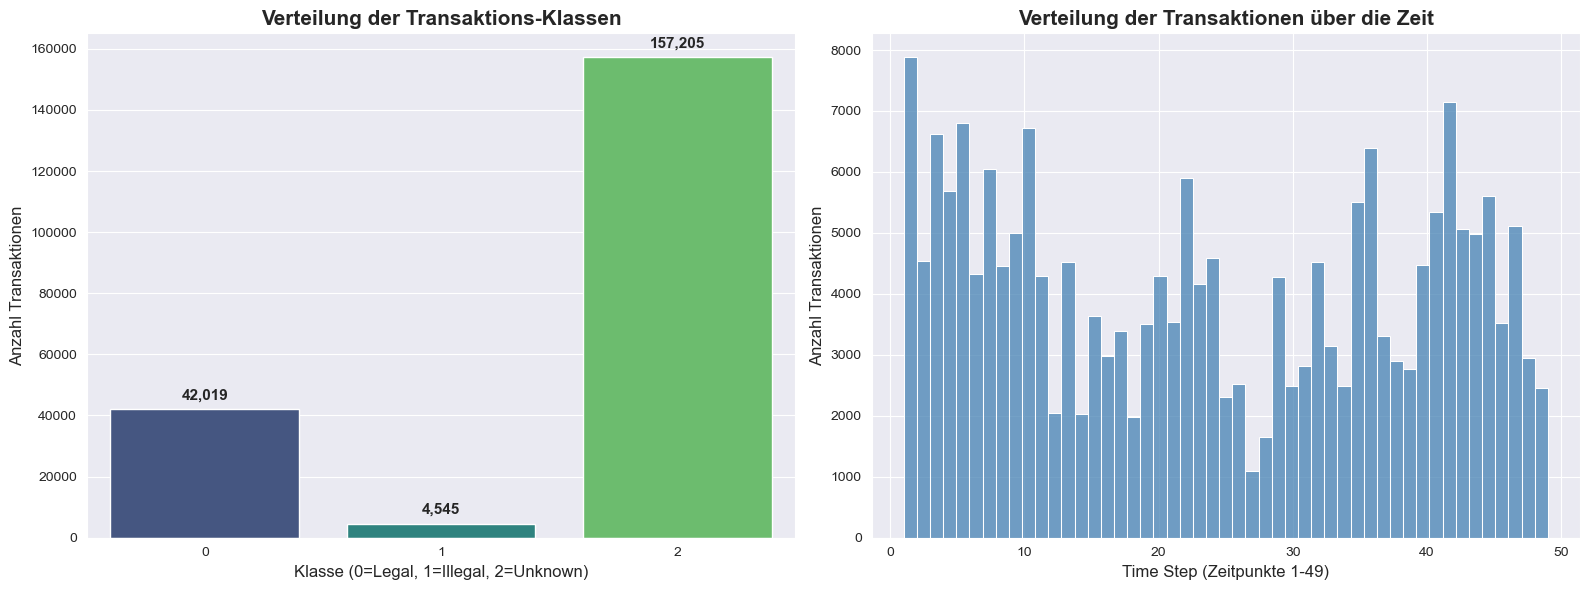

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Setup
sns.set_style("darkgrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Klassen-Verteilung mit Reihenfolge
ax1 = sns.countplot(data=df_nodes, x='class', palette="viridis", ax=axes[0], order=[0, 1, 2])
axes[0].set_title('Verteilung der Transaktions-Klassen', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Klasse (0=Legal, 1=Illegal, 2=Unknown)', fontsize=12)
axes[0].set_ylabel('Anzahl Transaktionen', fontsize=12)

# Labels für die Balken
for p in ax1.patches:
    height = p.get_height()
    if height > 0:  # Nur wenn Höhe > 0
        ax1.annotate(f'{int(height):,}', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='center', 
                    xytext=(0, 10), 
                    textcoords='offset points',
                    fontsize=11, fontweight='bold')

# Zeitliche Verteilung
ax2 = sns.histplot(data=df_nodes, x='time_step', bins=49, color='steelblue', ax=axes[1])
axes[1].set_title('Verteilung der Transaktionen über die Zeit', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Time Step (Zeitpunkte 1-49)', fontsize=12)
axes[1].set_ylabel('Anzahl Transaktionen', fontsize=12)

plt.tight_layout()
plt.show()

In [15]:
### 2. Graph Features

In [16]:
### 2.1 Graph-features berechenen

In [17]:
import networkx as nx
import pandas as pd

# 1. Graph erstellen 
G = nx.from_pandas_edgelist(df_edges, source='txId1', target='txId2', create_using=nx.DiGraph())
print(f"Graph erstellt! Knoten: {G.number_of_nodes()}, Kanten: {G.number_of_edges()}")

# 2. Features berechnen
in_degree = dict(G.in_degree())   
out_degree = dict(G.out_degree()) 

pagerank = nx.pagerank(G)
clustering = nx.clustering(G.to_undirected())

# 3. Features in einen DataFrame packen
df_graph_features = pd.DataFrame({
    'txId': list(G.nodes()),
    'in_degree': [in_degree.get(n, 0) for n in G.nodes()],
    'out_degree': [out_degree.get(n, 0) for n in G.nodes()],
    'pagerank': [pagerank.get(n, 0) for n in G.nodes()],
    'clustering': [clustering.get(n, 0) for n in G.nodes()]
})

# 4. Mit Haupt-Datensatz (df_nodes) verbinden
df_enriched = pd.merge(df_nodes, df_graph_features, on='txId', how='left')

# NaN mit 0 füllen (falls Knoten keine Kanten hatten)
df_enriched.fillna(0, inplace=True)

display(df_enriched[['txId', 'class', 'in_degree', 'out_degree', 'pagerank', 'clustering']].head())

Graph erstellt! Knoten: 203769, Kanten: 234355


,txId,class,in_degree,out_degree,pagerank,clustering
0,230425980,2,1,1,0.000005,0.000000
1,5530458,2,1,1,0.000006,0.000000
2,232022460,2,1,2,0.000007,0.000000
3,232438397,0,160,1,0.000351,0.000621
4,230460314,2,2,8,0.000002,0.266667


In [18]:
### 2.2 Unkown filtern

In [19]:
df_final = df_enriched[df_enriched['class'] != 2].copy()

print(f"Ursprüngliche Größe: {df_enriched.shape}")
print(f"Neue Größe: {df_final.shape}")

# 0 = Legal, 1 = Illegal
print(df_final['class'].value_counts())

Ursprüngliche Größe: (203769, 172)
Neue Größe: (46564, 172)
class
0    42019
1     4545
Name: count, dtype: int64


In [20]:
### 2.3 VIF Analyse

In [21]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Features für VIF-Analyse vorbereiten
X_vif = df_final.drop(columns=['class', 'txId', 'time_step'])

print(f"\nVIF-Analyse auf {X_vif.shape[1]} Features. Bitte warten...")

# DataFrame für Ergebnisse
vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif.columns

# VIF berechnen
vif_list = []
for i in range(len(X_vif.columns)):
    vif = variance_inflation_factor(X_vif.values, i)
    vif_list.append(vif)
    
    if i % 20 == 0:
        print(f"   ... {i} Features berechnet")

vif_data["VIF"] = vif_list
vif_data = vif_data.sort_values(by="VIF", ascending=False)

print(f"\nVIF-Analyse abgeschlossen für {len(vif_list)} Features!")
display(vif_data.head(10))


VIF-Analyse auf 169 Features. Bitte warten...
   ... 0 Features berechnet
   ... 20 Features berechnet
   ... 40 Features berechnet
   ... 60 Features berechnet
   ... 80 Features berechnet
   ... 100 Features berechnet
   ... 120 Features berechnet
   ... 140 Features berechnet
   ... 160 Features berechnet

VIF-Analyse abgeschlossen für 169 Features!


,Feature,VIF
60,feat_60,inf
72,feat_72,inf
66,feat_66,inf
36,feat_36,8.398380e+08
29,feat_29,6.907890e+08
21,feat_21,2.699152e+08
30,feat_30,2.055756e+08
59,feat_59,1.835650e+08
63,feat_63,1.079132e+08
57,feat_57,1.045116e+08


In [22]:
### 2.4 Feature nach VIF entfernen

In [23]:
import networkx as nx
import pandas as pd
import numpy as np

# Features & Target trennen
X = df_final.drop(columns=['class', 'txId', 'time_step'])
y = df_final['class']

# Korrelationsmatrix berechnen
corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = [column for column in upper.columns if any(upper[column] > 0.9)]

print(f"   Gefundene Duplikate: {len(to_drop)} Features")

# Features entfernen
X_reduced = X.drop(columns=to_drop)

print(f"   Features vorher: {X.shape[1]}")
print(f"   Features nachher: {X_reduced.shape[1]}")
# X mit X_reduced ersetzen für weitere Verarbeitung
X = X_reduced

   Gefundene Duplikate: 73 Features
   Features vorher: 169
   Features nachher: 96


In [24]:
### 2.5 Temporal  & Ziel/Target trennung

In [25]:
### 2.5 Temporal Split 
print("=== TEMPORALER SPLIT ===")
print("Training: Time Steps 1-34")
print("Test: Time Steps 35-49")

# Temporaler Split basierend auf time_step
train_mask = df_final['time_step'] <= 34
test_mask = df_final['time_step'] >= 35

# Split durchführen
X_train = X[train_mask].copy()
X_test = X[test_mask].copy()
y_train = y[train_mask].copy()
y_test = y[test_mask].copy()

print(f"\nTraining Daten:")
print(f"   Anzahl Samples: {len(X_train)}")
print(f"   Time Steps: {df_final.loc[train_mask, 'time_step'].min()} - {df_final.loc[train_mask, 'time_step'].max()}")
print(f"   Klassenverteilung:\n{y_train.value_counts()}")

print(f"\nTest Daten:")
print(f"   Anzahl Samples: {len(X_test)}")
print(f"   Time Steps: {df_final.loc[test_mask, 'time_step'].min()} - {df_final.loc[test_mask, 'time_step'].max()}")
print(f"   Klassenverteilung:\n{y_test.value_counts()}")

=== TEMPORALER SPLIT ===
Training: Time Steps 1-34
Test: Time Steps 35-49

Training Daten:
   Anzahl Samples: 29894
   Time Steps: 1 - 34
   Klassenverteilung:
class
0    26432
1     3462
Name: count, dtype: int64

Test Daten:
   Anzahl Samples: 16670
   Time Steps: 35 - 49
   Klassenverteilung:
class
0    15587
1     1083
Name: count, dtype: int64


In [26]:
### 2.6 Feature skalierung

In [27]:
from sklearn.preprocessing import StandardScaler

# Skalierung 
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print(f"Skalierung abgeschlossen!")
print(f"   X_train_scaled: {X_train_scaled.shape}")
print(f"   X_test_scaled: {X_test_scaled.shape}")
print(f"   y_train: {y_train.shape}")
print(f"   y_test: {y_test.shape}")

# Verifikation
print(f"\nVerifikation:")
print(f"   X_train_scaled Samples: {len(X_train_scaled)}")
print(f"   y_train Samples: {len(y_train)}")
print(f"   Stimmen überein: {len(X_train_scaled) == len(y_train)}")

Skalierung abgeschlossen!
   X_train_scaled: (29894, 96)
   X_test_scaled: (16670, 96)
   y_train: (29894,)
   y_test: (16670,)

Verifikation:
   X_train_scaled Samples: 29894
   y_train Samples: 29894
   Stimmen überein: True


In [28]:
### 2.7 Visualisierung

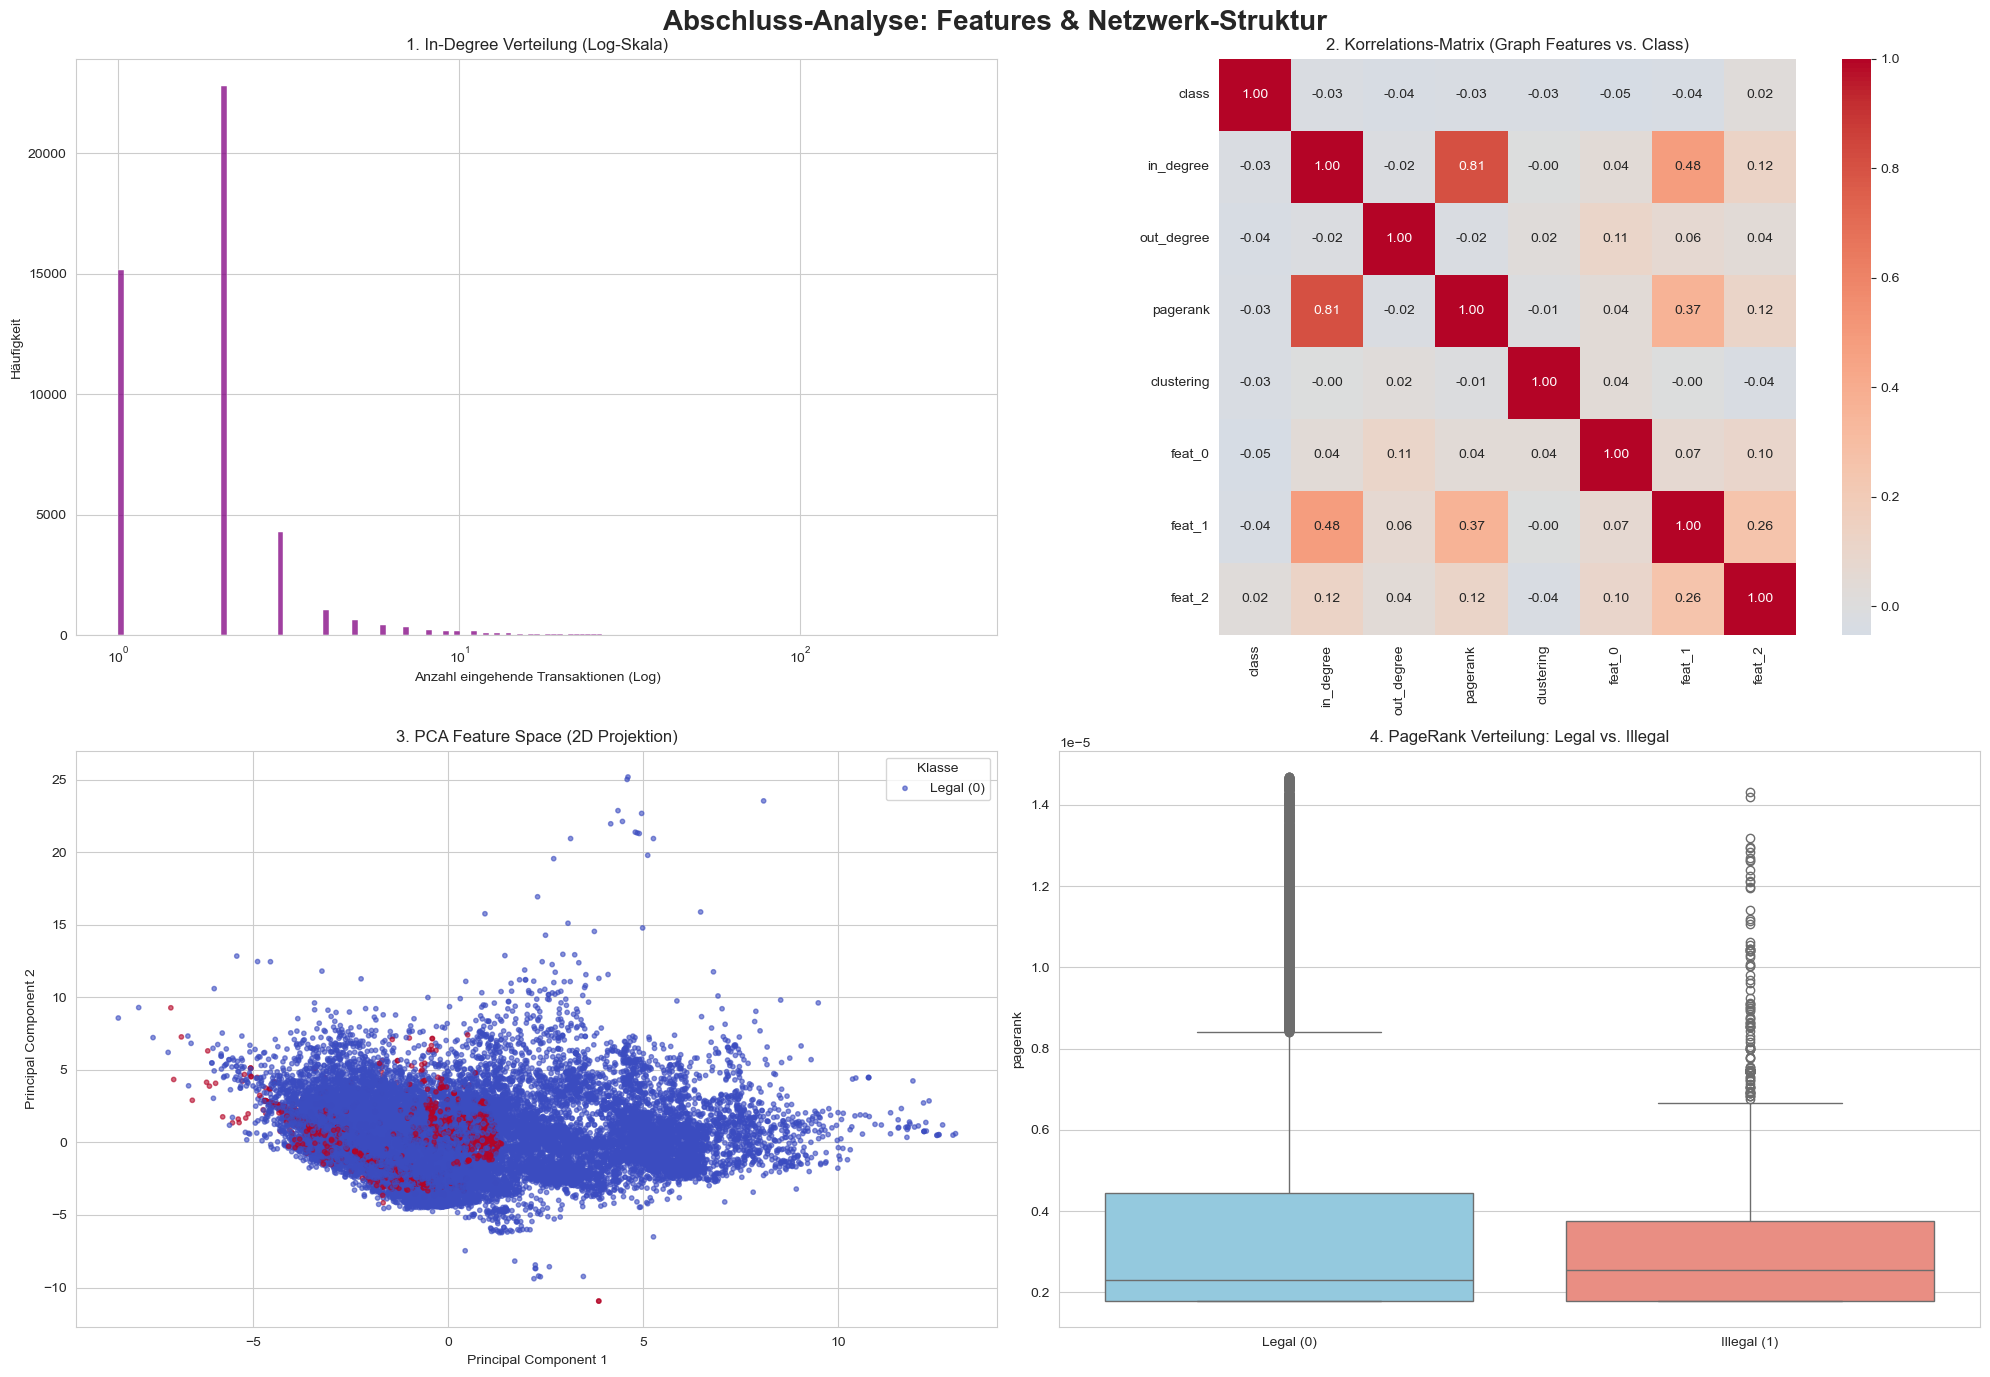

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Setup
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(20, 14))
fig.suptitle("Abschluss-Analyse: Features & Netzwerk-Struktur", fontsize=20, fontweight='bold')

# 1. Degree Verteilung
sns.histplot(df_final['in_degree'] + 1, log_scale=True, color="purple", ax=axes[0,0])
axes[0,0].set(title="1. In-Degree Verteilung (Log-Skala)", 
               xlabel="Anzahl eingehende Transaktionen (Log)", 
               ylabel="Häufigkeit")

# 2. Korrelations-Heatmap
cols = ['class', 'in_degree', 'out_degree', 'pagerank', 'clustering'] + X_train_scaled.columns[:3].tolist()
sns.heatmap(df_final[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", 
            center=0, ax=axes[0,1], square=True)
axes[0,1].set_title("2. Korrelations-Matrix (Graph Features vs. Class)")

# 3. PCA Visualisierung
X_pca = PCA(n_components=2).fit_transform(X_train_scaled)
scatter = axes[1,0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_train, cmap='coolwarm', alpha=0.6, s=10)
axes[1,0].set(title="3. PCA Feature Space (2D Projektion)",
              xlabel="Principal Component 1", 
              ylabel="Principal Component 2")
legend_labels = ['Legal (0)', 'Illegal (1)']
axes[1,0].legend(*scatter.legend_elements(), labels=legend_labels, title="Klasse")

# 4. PageRank Boxplot
plot_data = df_final[df_final['pagerank'] < df_final['pagerank'].quantile(0.95)].copy()
plot_data['class_str'] = plot_data['class'].astype(str)  # Konvertiere zu String für seaborn
sns.boxplot(x='class_str', y='pagerank', data=plot_data, 
            palette={'0': "skyblue", '1': "salmon"}, ax=axes[1,1])  
axes[1,1].set(title="4. PageRank Verteilung: Legal vs. Illegal", 
              xticklabels=['Legal (0)', 'Illegal (1)'], xlabel="")

plt.tight_layout()
plt.show()

In [30]:
### 3.SMOTE

In [31]:
### 3.1 SMOTE

In [32]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote_array, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# Zurück zu DataFrame konvertieren
X_train_smote = pd.DataFrame(
    X_train_smote_array,
    columns=X_train_scaled.columns
)

print(f"Vor SMOTE: {X_train_scaled.shape[0]} Samples")
print(f"Nach SMOTE: {X_train_smote.shape[0]} Samples")
print(f"Klasse Verteilung nach SMOTE: {pd.Series(y_train_smote).value_counts().to_dict()}")

Vor SMOTE: 29894 Samples
Nach SMOTE: 52864 Samples
Klasse Verteilung nach SMOTE: {0: 26432, 1: 26432}


In [33]:
### 4. Logistische Regression 

In [34]:
### 4.1 Modell Training 

In [35]:
from sklearn.linear_model import LogisticRegression

lr_no_smote = LogisticRegression(random_state=42, max_iter=1000 )
lr_no_smote.fit(X_train_scaled, y_train)
print("Logistische Regression (ohne SMOTE) trainiert")

Logistische Regression (ohne SMOTE) trainiert


In [36]:
### 4.2 Modell Training mit SMOTE

In [37]:
lr_with_smote = LogisticRegression(random_state=42, max_iter=1000 )
lr_with_smote.fit(X_train_smote, y_train_smote)
print("Logistische Regression (mit SMOTE) trainiert")

Logistische Regression (mit SMOTE) trainiert


In [38]:
### 4.3 Vorhersage ohne SMOTE

In [39]:
y_pred_no_smote = lr_no_smote.predict(X_test_scaled)
y_pred_proba_no_smote = lr_no_smote.predict_proba(X_test_scaled)[:, 1]
print("Vorhersagen (ohne SMOTE) erstellt")

Vorhersagen (ohne SMOTE) erstellt


In [40]:
### 4.4 Vorhersage mit SMOTE

In [41]:
y_pred_with_smote = lr_with_smote.predict(X_test_scaled)
y_pred_proba_with_smote = lr_with_smote.predict_proba(X_test_scaled)[:, 1]
print("Vorhersagen (mit SMOTE) erstellt")

Vorhersagen (mit SMOTE) erstellt


In [42]:
### 4.5 Evaluation ohne SMOTE

In [43]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
print("\nClassification Report:")
print(classification_report(y_test, y_pred_no_smote))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_no_smote))
print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_no_smote):.4f}")


Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.87      0.92     15587
           1       0.26      0.65      0.37      1083

    accuracy                           0.86     16670
   macro avg       0.62      0.76      0.65     16670
weighted avg       0.93      0.86      0.88     16670


Confusion Matrix:
[[13606  1981]
 [  381   702]]

ROC-AUC Score: 0.8832


In [44]:
### 4.6 Evaluation mit SMOTE

In [45]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred_with_smote))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_with_smote))
print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_with_smote):.4f}")


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.72      0.83     15587
           1       0.17      0.84      0.29      1083

    accuracy                           0.73     16670
   macro avg       0.58      0.78      0.56     16670
weighted avg       0.93      0.73      0.80     16670


Confusion Matrix:
[[11257  4330]
 [  169   914]]

ROC-AUC Score: 0.8729


In [46]:
### 5.0 Random Forest

In [47]:
### 5.1 Modell Training

In [48]:
# Random Forest OHNE SMOTE
from sklearn.ensemble import RandomForestClassifier
rf_no_smote = RandomForestClassifier(random_state=42, n_jobs=-1, n_estimators=200)
rf_no_smote.fit(X_train_scaled, y_train)
print("Random Forest (ohne SMOTE) trainiert")

Random Forest (ohne SMOTE) trainiert


In [49]:
### 5.2 Modell Training mit SMOTE

In [50]:
# Random Forest MIT SMOTE
rf_with_smote = RandomForestClassifier(random_state=42, n_jobs=-1, n_estimators=200)
rf_with_smote.fit(X_train_smote, y_train_smote)
print("Random Forest (mit SMOTE) trainiert")

Random Forest (mit SMOTE) trainiert


In [51]:
### 5.3 Vorhersagen

In [52]:
# Vorhersagen OHNE SMOTE
y_pred_rf_no_smote = rf_no_smote.predict(X_test_scaled)
y_pred_proba_rf_no_smote = rf_no_smote.predict_proba(X_test_scaled)[:, 1]
print("Vorhersagen (ohne SMOTE) erstellt")

# Vorhersagen MIT SMOTE
y_pred_rf_with_smote = rf_with_smote.predict(X_test_scaled)
y_pred_proba_rf_with_smote = rf_with_smote.predict_proba(X_test_scaled)[:, 1]
print("Vorhersagen (mit SMOTE) erstellt")

Vorhersagen (ohne SMOTE) erstellt
Vorhersagen (mit SMOTE) erstellt


In [53]:
### 5.4 Evaluation

In [54]:
# Evaluation OHNE SMOTE
print("=== Random Forest OHNE SMOTE ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_no_smote))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_no_smote))
print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_rf_no_smote):.4f}")

# Evaluation MIT SMOTE
print("=== Random Forest MIT SMOTE ===")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_with_smote))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf_with_smote))
print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_rf_with_smote):.4f}")

=== Random Forest OHNE SMOTE ===

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     15587
           1       0.97      0.72      0.82      1083

    accuracy                           0.98     16670
   macro avg       0.98      0.86      0.91     16670
weighted avg       0.98      0.98      0.98     16670


Confusion Matrix:
[[15566    21]
 [  308   775]]

ROC-AUC Score: 0.9275
=== Random Forest MIT SMOTE ===

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     15587
           1       0.92      0.71      0.80      1083

    accuracy                           0.98     16670
   macro avg       0.95      0.85      0.90     16670
weighted avg       0.98      0.98      0.98     16670


Confusion Matrix:
[[15523    64]
 [  313   770]]

ROC-AUC Score: 0.9418


In [55]:
### 6.0 XGBosst

In [56]:
### 6.1 Modell Training

In [57]:
# XGBoost OHNE SMOTE
import xgboost as xgb

xgb_no_smote = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss' )
xgb_no_smote.fit(X_train_scaled, y_train)
print("XGBoost (ohne SMOTE) trainiert")

XGBoost (ohne SMOTE) trainiert


In [58]:
### 6.2 Modell Training mit SMOTE

In [59]:
# XGBoost MIT SMOTE
xgb_with_smote = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss' )
xgb_with_smote.fit(X_train_smote, y_train_smote)
print("XGBoost (mit SMOTE) trainiert")

XGBoost (mit SMOTE) trainiert


In [60]:
### 6.3 Vorhersagen

In [61]:
# Vorhersagen OHNE SMOTE
y_pred_xgb_no_smote = xgb_no_smote.predict(X_test_scaled)
y_pred_proba_xgb_no_smote = xgb_no_smote.predict_proba(X_test_scaled)[:, 1]
print("Vorhersagen (ohne SMOTE) erstellt")

# Vorhersagen MIT SMOTE
y_pred_xgb_with_smote = xgb_with_smote.predict(X_test_scaled)
y_pred_proba_xgb_with_smote = xgb_with_smote.predict_proba(X_test_scaled)[:, 1]
print("Vorhersagen (mit SMOTE) erstellt")

Vorhersagen (ohne SMOTE) erstellt
Vorhersagen (mit SMOTE) erstellt


In [62]:
### 6.4 Evaluation

In [63]:
# Evaluation OHNE SMOTE
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_no_smote))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_no_smote))
print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_xgb_no_smote):.4f}")

# Evaluation MIT SMOTE
print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb_with_smote))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb_with_smote))
print(f"\nROC-AUC Score: {roc_auc_score(y_test, y_pred_proba_xgb_with_smote):.4f}")


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99     15587
           1       0.90      0.72      0.80      1083

    accuracy                           0.98     16670
   macro avg       0.94      0.86      0.89     16670
weighted avg       0.98      0.98      0.98     16670


Confusion Matrix:
[[15497    90]
 [  304   779]]

ROC-AUC Score: 0.9299

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     15587
           1       0.92      0.73      0.81      1083

    accuracy                           0.98     16670
   macro avg       0.95      0.86      0.90     16670
weighted avg       0.98      0.98      0.98     16670


Confusion Matrix:
[[15518    69]
 [  294   789]]

ROC-AUC Score: 0.9411


In [64]:
### 7. Cross validation 

In [65]:
### 7.1 Datavorbereitung

In [66]:
train_indices_sorted = X_train.index.to_frame().merge(
    df_final[['time_step']], left_index=True, right_index=True, how='left'
).sort_values('time_step').index

X_train_sorted = X_train_scaled.loc[train_indices_sorted]
y_train_sorted = y_train.loc[train_indices_sorted]

In [67]:
### 7.1 Setup

In [68]:
from sklearn.model_selection import cross_val_score, TimeSeriesSplit
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTE
from sklearn.base import clone
import numpy as np

cv = TimeSeriesSplit(n_splits=5)

def cv_with_smote(model, X, y):
    scores = []
    smote = SMOTE(random_state=42)
    for train_idx, val_idx in cv.split(X, y):
        X_train_fold, y_train_fold = X.iloc[train_idx], y.iloc[train_idx]
        X_val_fold, y_val_fold = X.iloc[val_idx], y.iloc[val_idx]
        X_smote, y_smote = smote.fit_resample(X_train_fold, y_train_fold)
        model_fold = clone(model).fit(X_smote, y_smote)
        scores.append(roc_auc_score(y_val_fold, model_fold.predict_proba(X_val_fold)[:, 1]))
    return np.array(scores)

In [69]:
### 7.2 Crossvalidation

In [70]:
models_cv = {
    'LR (ohne SMOTE)': (lr_no_smote, X_train_sorted, y_train_sorted, False),
    'LR (mit SMOTE)': (lr_with_smote, X_train_sorted, y_train_sorted, True),
    'RF (ohne SMOTE)': (rf_no_smote, X_train_sorted, y_train_sorted, False),
    'RF (mit SMOTE)': (rf_with_smote, X_train_sorted, y_train_sorted, True),
    'XGB (ohne SMOTE)': (xgb_no_smote, X_train_sorted, y_train_sorted, False),
    'XGB (mit SMOTE)': (xgb_with_smote, X_train_sorted, y_train_sorted, True)
}

cv_results = {}
for name, (model, X, y, use_smote) in models_cv.items():
    scores = cv_with_smote(model, X, y) if use_smote else cross_val_score(model, X, y, cv=cv, scoring='roc_auc')
    cv_results[name] = scores
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std()*2:.4f})")

LR (ohne SMOTE): 0.9192 (+/- 0.0769)
LR (mit SMOTE): 0.9158 (+/- 0.0769)
RF (ohne SMOTE): 0.9635 (+/- 0.0765)
RF (mit SMOTE): 0.9587 (+/- 0.0965)
XGB (ohne SMOTE): 0.9628 (+/- 0.0797)
XGB (mit SMOTE): 0.9669 (+/- 0.0671)


In [71]:
### 8.0 Evaluation

In [72]:
### 8.1 Evaluation

In [73]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

predictions = {
    'LR (ohne SMOTE)': (y_pred_no_smote, y_pred_proba_no_smote),
    'LR (mit SMOTE)': (y_pred_with_smote, y_pred_proba_with_smote),
    'RF (ohne SMOTE)': (y_pred_rf_no_smote, y_pred_proba_rf_no_smote),
    'RF (mit SMOTE)': (y_pred_rf_with_smote, y_pred_proba_rf_with_smote),
    'XGB (ohne SMOTE)': (y_pred_xgb_no_smote, y_pred_proba_xgb_no_smote),
    'XGB (mit SMOTE)': (y_pred_xgb_with_smote, y_pred_proba_xgb_with_smote)
}

final_df = pd.DataFrame([{
    'Modell': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba)
} for name, (y_pred, y_pred_proba) in predictions.items()]).sort_values('ROC-AUC', ascending=False)

display(final_df.round(4))

,Modell,Accuracy,Precision,Recall,F1-Score,ROC-AUC
3,RF (mit SMOTE),0.9774,0.9233,0.7110,0.8033,0.9418
5,XGB (mit SMOTE),0.9782,0.9196,0.7285,0.8130,0.9411
4,XGB (ohne SMOTE),0.9764,0.8964,0.7193,0.7982,0.9299
2,RF (ohne SMOTE),0.9803,0.9736,0.7156,0.8249,0.9275
0,LR (ohne SMOTE),0.8583,0.2616,0.6482,0.3728,0.8832
1,LR (mit SMOTE),0.7301,0.1743,0.8440,0.2889,0.8729


In [74]:
### 8.2 Visualisierung

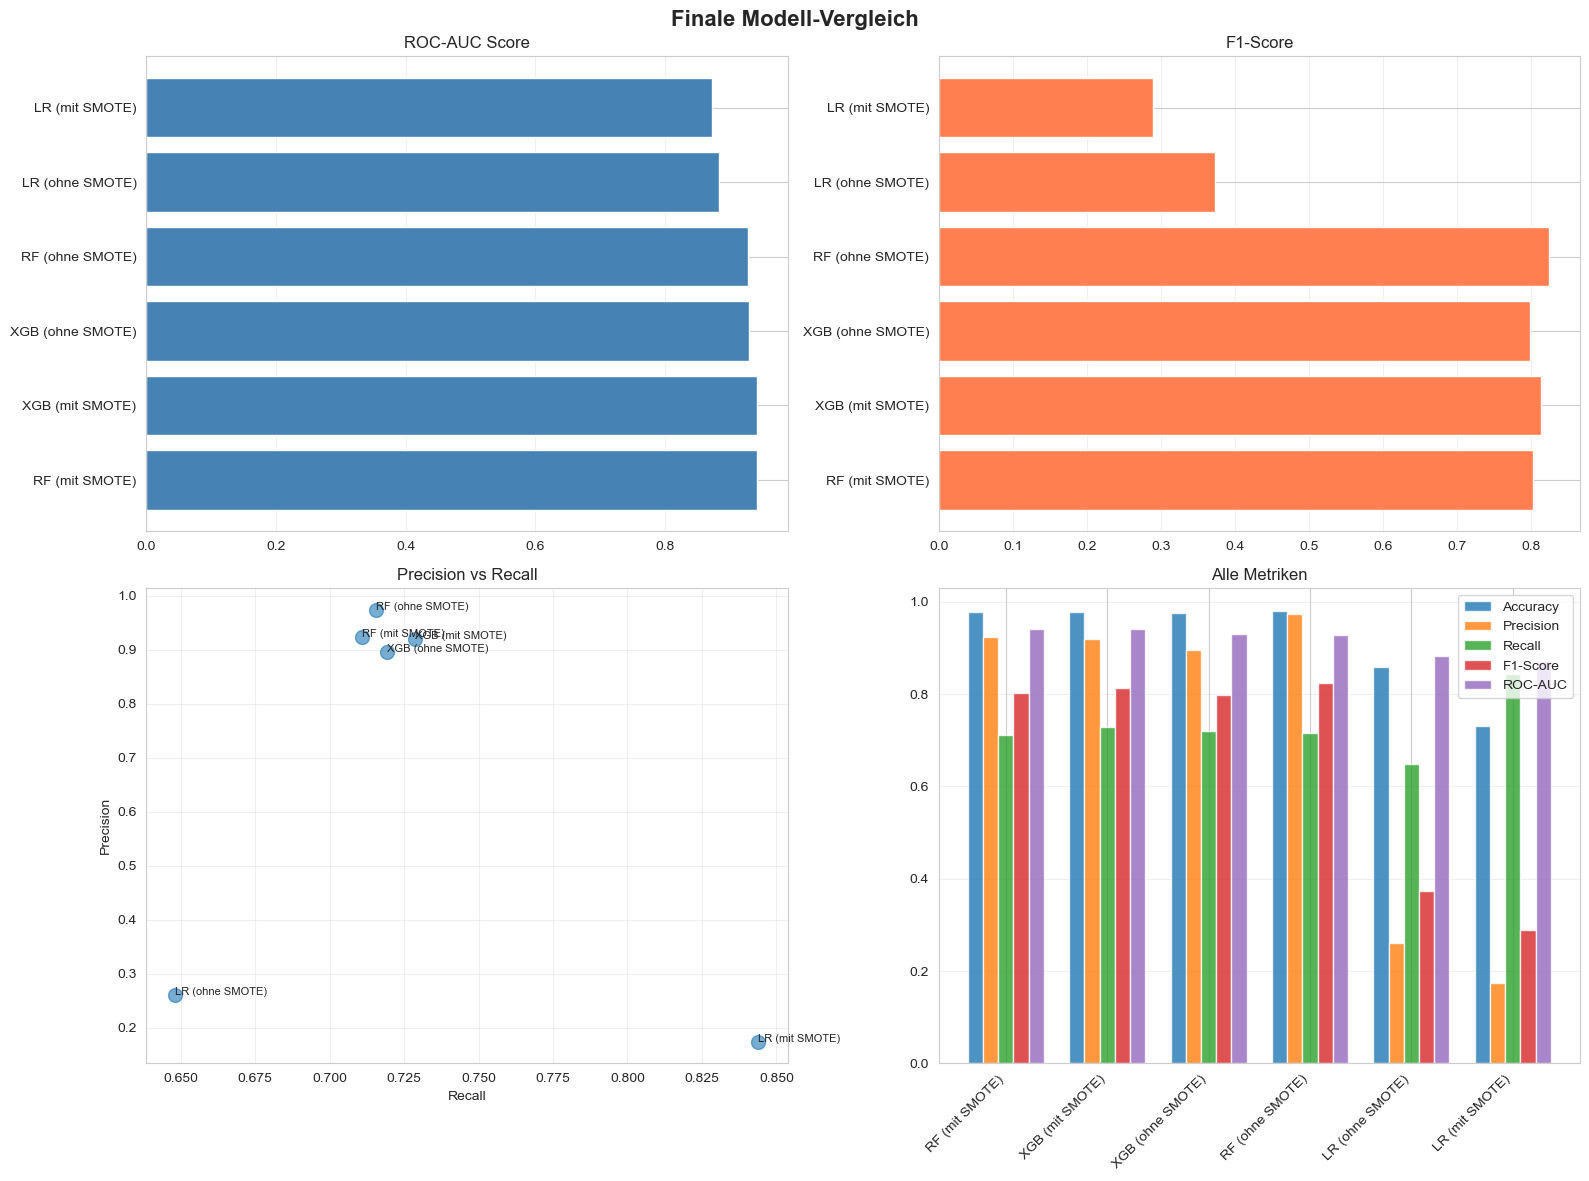

In [75]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Finale Modell-Vergleich', fontsize=16, fontweight='bold')

axes[0, 0].barh(final_df['Modell'], final_df['ROC-AUC'], color='steelblue')
axes[0, 0].set_title('ROC-AUC Score')
axes[0, 0].grid(axis='x', alpha=0.3)

axes[0, 1].barh(final_df['Modell'], final_df['F1-Score'], color='coral')
axes[0, 1].set_title('F1-Score')
axes[0, 1].grid(axis='x', alpha=0.3)

axes[1, 0].scatter(final_df['Recall'], final_df['Precision'], s=100, alpha=0.6)
for i, m in enumerate(final_df['Modell']):
    axes[1, 0].annotate(m, (final_df['Recall'].iloc[i], final_df['Precision'].iloc[i]), fontsize=8)
axes[1, 0].set_xlabel('Recall')
axes[1, 0].set_ylabel('Precision')
axes[1, 0].set_title('Precision vs Recall')
axes[1, 0].grid(alpha=0.3)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
x = range(len(final_df))
for i, m in enumerate(metrics):
    axes[1, 1].bar([xi + i*0.15 for xi in x], final_df[m], 0.15, label=m, alpha=0.8)
axes[1, 1].set_xticks([xi + 0.3 for xi in x])
axes[1, 1].set_xticklabels(final_df['Modell'], rotation=45, ha='right')
axes[1, 1].legend()
axes[1, 1].set_title('Alle Metriken')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()